In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Required Imports
from keras.layers import Flatten, Dense
from keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
from sklearn.metrics import roc_curve, auc
import os

In [3]:
noOfClasses = 5
class_names = ["Aristolochia_indica", "Centella_asiatica", "Giant_calotrope", "Green_chiretta", "Terminalia_bellirica"]

In [4]:
train_path = '/content/drive/Shareddrives/Thesis_Preparation/THT_Medicinal/data/train'
valid_path = '/content/drive/Shareddrives/Thesis_Preparation/THT_Medicinal/data/eval'
test_path = '/content/drive/Shareddrives/Thesis_Preparation/THT_Medicinal/data/test'

In [5]:
train_dataset = ImageDataGenerator(rescale=1/255).flow_from_directory(
    directory=train_path, target_size=(224, 224), classes=class_names)

valid_dataset = ImageDataGenerator(rescale=1/255).flow_from_directory(
    directory=valid_path, target_size=(224, 224), classes=class_names)

test_dataset = ImageDataGenerator(rescale=1/255).flow_from_directory(
    directory=test_path, target_size=(224, 224), classes=class_names, shuffle=False)

Found 4820 images belonging to 5 classes.
Found 1030 images belonging to 5 classes.
Found 1040 images belonging to 5 classes.


In [7]:
# Model Selector Function
def get_model(model_name, noOfClasses, layers_to_unfreeze=10):
    # Model Selector Function
    if model_name == "Inceptionv3":
        base_model = tf.keras.applications.InceptionV3(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    elif model_name == "AlexNet":
        base_model = tf.keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    elif model_name == "VGG19":
        base_model = tf.keras.applications.VGG19(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    elif model_name == "DenseNet201":
        base_model = tf.keras.applications.DenseNet201(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    elif model_name == "MobileNetV3":
        base_model = tf.keras.applications.MobileNetV3Large(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    elif model_name == "MobileNetV2":
        base_model = tf.keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    elif model_name == "ResNet50V2":
        base_model = tf.keras.applications.ResNet50V2(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    else:
        raise ValueError(f"Model {model_name} is not supported.")

    # Freeze all layers except the top layers
    for layer in base_model.layers[:-layers_to_unfreeze]:
        layer.trainable = False

    x = Flatten()(base_model.output)
    prediction = Dense(noOfClasses, activation='softmax')(x)
    model = Model(inputs=base_model.input, outputs=prediction)
    return model

In [8]:
# Parameter Initialization
def initiateParams(className, model, lr, model_name):
    opt = tf.keras.optimizers.Adam(learning_rate=lr)
    model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])
    annealer = ReduceLROnPlateau(monitor='val_accuracy', factor=0.5, patience=15, verbose=1, min_lr=1e-5)
    checkpoint = ModelCheckpoint(className + model_name + '.keras', save_best_only=True, monitor="val_accuracy")
    early_stopping = EarlyStopping(monitor="val_accuracy", patience=10, restore_best_weights=True)
    return model, [annealer,checkpoint, early_stopping]

In [9]:
# Training Function
def modelFit(model, callbacks, train_dataset, valid_dataset, epochs=15, batchSize=128):
    history = model.fit(
        train_dataset,
        validation_data=valid_dataset,
        epochs=epochs,
        batch_size=batchSize,
        callbacks=callbacks,
    )
    return history

In [10]:
# List of available models to choose from
model_names = ["Inceptionv3", "VGG19", "DenseNet201", "MobileNetV2", "ResNet50V2"]

model_name = "Inceptionv3"

print(f"\nTraining {model_name}...")
model = get_model(model_name, noOfClasses, layers_to_unfreeze=10)
model, callbacks = initiateParams("Model_", model, 1e-4, model_name)
history = modelFit(model, callbacks, train_dataset, valid_dataset, epochs=15)


Training Inceptionv3...
87910968/87910968 [==============================] - 1s 0us/step
Epoch 1/15
151/151 [==============================] - 2337s 15s/step - loss: 0.3222 - accuracy: 0.8826 - val_loss: 0.4777 - val_accuracy: 0.8223 - lr: 1.0000e-04
Epoch 2/15
151/151 [==============================] - 49s 326ms/step - loss: 0.0745 - accuracy: 0.9807 - val_loss: 0.4122 - val_accuracy: 0.8641 - lr: 1.0000e-04
Epoch 3/15
151/151 [==============================] - 48s 315ms/step - loss: 0.0371 - accuracy: 0.9946 - val_loss: 0.3875 - val_accuracy: 0.8592 - lr: 1.0000e-04
Epoch 4/15
151/151 [==============================] - 49s 326ms/step - loss: 0.0220 - accuracy: 0.9977 - val_loss: 0.3923 - val_accuracy: 0.8689 - lr: 1.0000e-04
Epoch 5/15
151/151 [==============================] - 50s 325ms/step - loss: 0.0145 - accuracy: 0.9996 - val_loss: 0.3891 - val_accuracy: 0.8650 - lr: 1.0000e-04
Epoch 6/15
151/151 [==============================] - 48s 320ms/step - loss: 0.0103 - accuracy: 1.00

In [11]:
# Plot Training and Validation Loss/Accuracy
def plotOutput(history, modelName, epochs):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    # Get the actual number of epochs the model was trained for
    num_epochs = len(acc)

    plt.figure(figsize=(12, 12))
    plt.subplot(3, 2, 1)
    # Use num_epochs for x-axis data to match the length of y data
    plt.plot(range(num_epochs), acc, label='Training Accuracy')
    plt.plot(range(num_epochs), val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')

    plt.subplot(3, 2, 2)
    # Use num_epochs for x-axis data to match the length of y data
    plt.plot(range(num_epochs), loss, label='Training Loss')
    plt.plot(range(num_epochs), val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')
    plt.savefig(modelName + '_graph.png')
    plt.show()

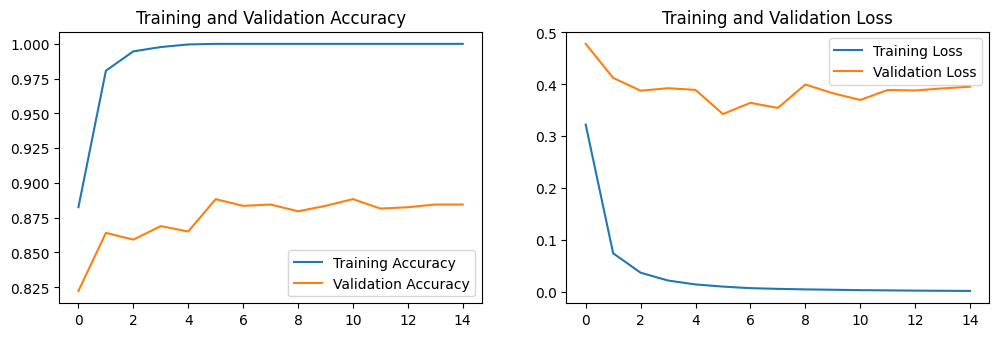

In [12]:
plotOutput(history, model_name, 250)

In [13]:
# Evaluation Function
def Validation(model, valid_dataset):
    evl = model.evaluate(valid_dataset)
    acc = evl[1] * 100
    msg = f'Accuracy on the Test Set = {acc: .2f} %'
    print(msg)
    return acc

In [14]:
accuracy = Validation(model, valid_dataset)

33/33 [==============================] - 9s 253ms/step - loss: 0.3952 - accuracy: 0.8845
Accuracy on the Test Set =  88.45 %


33/33 [==============================] - 10s 249ms/step


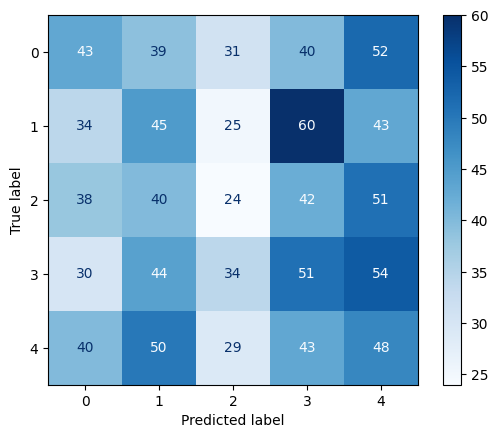

In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Assuming 'model' and 'test_dataset' are defined as in the previous code
y_true = valid_dataset.classes
y_pred = np.argmax(model.predict(valid_dataset), axis=1)

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1,2,3,4])
disp.plot(cmap=plt.cm.Blues)
plt.show()

In [16]:
from sklearn.metrics import classification_report

# Assuming 'model' and 'test_dataset' are defined as in the previous code
y_true = valid_dataset.classes
y_pred = np.argmax(model.predict(valid_dataset), axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

33/33 [==============================] - 9s 253ms/step
                      precision    recall  f1-score   support

 Aristolochia_indica       0.22      0.20      0.21       205
   Centella_asiatica       0.16      0.16      0.16       207
     Giant_calotrope       0.17      0.13      0.15       195
      Green_chiretta       0.21      0.23      0.22       213
Terminalia_bellirica       0.18      0.21      0.19       210

            accuracy                           0.19      1030
           macro avg       0.19      0.19      0.19      1030
        weighted avg       0.19      0.19      0.19      1030



Testing

In [17]:
# Evaluation Function
def evalModel(model, test_dataset):
    evl = model.evaluate(test_dataset)
    acc = evl[1] * 100
    msg = f'Accuracy on the Test Set = {acc: .2f} %'
    print(msg)
    return acc

In [18]:
accuracy = evalModel(model, test_dataset)

33/33 [==============================] - 418s 13s/step - loss: 0.3434 - accuracy: 0.8894
Accuracy on the Test Set =  88.94 %


33/33 [==============================] - 8s 250ms/step


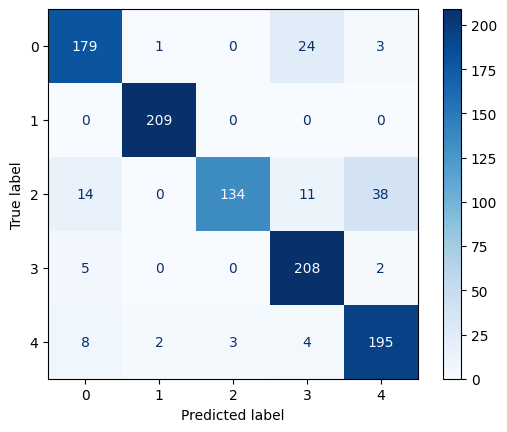

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Assuming 'model' and 'test_dataset' are defined as in the previous code
y_true = test_dataset.classes
y_pred = np.argmax(model.predict(test_dataset), axis=1)

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1,2,3,4])
disp.plot(cmap=plt.cm.Blues)
plt.show()

In [20]:
# ROC Curve Plotting
def plot_roc_curve(model, test_dataset, class_names):
    y_true = test_dataset.classes
    y_pred = model.predict(test_dataset)
    fpr = {}
    tpr = {}
    roc_auc = {}

    for i, class_name in enumerate(class_names):
        fpr[class_name], tpr[class_name], _ = roc_curve(y_true == i, y_pred[:, i])
        roc_auc[class_name] = auc(fpr[class_name], tpr[class_name])

    plt.figure()
    for i, class_name in enumerate(class_names):
        plt.plot(fpr[class_name], tpr[class_name], label=f'ROC curve (area = {roc_auc[class_name]:.2f}) for {class_name}')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC)')
    plt.legend(loc='lower right')
    plt.show()

33/33 [==============================] - 9s 255ms/step


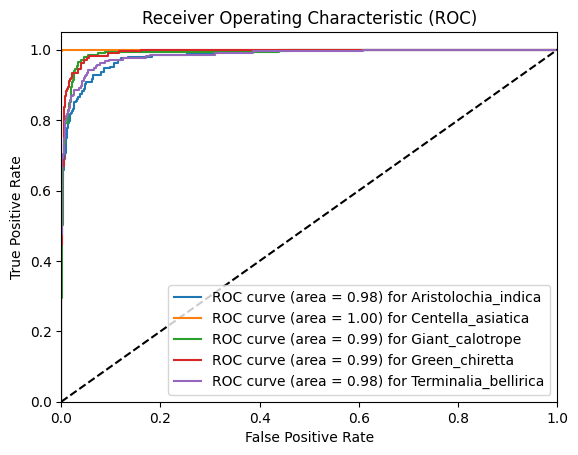

In [21]:
plot_roc_curve(model, test_dataset, class_names)

In [22]:
from sklearn.metrics import classification_report

# Assuming 'model' and 'test_dataset' are defined as in the previous code
y_true = test_dataset.classes
y_pred = np.argmax(model.predict(test_dataset), axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

33/33 [==============================] - 8s 241ms/step
                      precision    recall  f1-score   support

 Aristolochia_indica       0.87      0.86      0.87       207
   Centella_asiatica       0.99      1.00      0.99       209
     Giant_calotrope       0.98      0.68      0.80       197
      Green_chiretta       0.84      0.97      0.90       215
Terminalia_bellirica       0.82      0.92      0.87       212

            accuracy                           0.89      1040
           macro avg       0.90      0.89      0.89      1040
        weighted avg       0.90      0.89      0.89      1040



In [23]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

# Save the model.
with open('model.tflite', 'wb') as f:
  f.write(tflite_model)